# RapidNet → ASL sign-language classifier (transfer learning)
Freeze the early RapidNet layers, replace the 1000-class ImageNet head with a 36-class ASL head, and fine-tune.

**Before running:** `Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all`.

## 1. Check GPU

In [1]:
!nvidia-smi -L
import torch; print('torch', torch.__version__, '| CUDA:', torch.cuda.is_available())

GPU 0: Tesla T4 (UUID: GPU-f5143881-f8d2-849d-52a8-fdd1f84009c6)
torch 2.14.1+cu130 | CUDA: True


## 2. Get the official RapidNet code + install deps

In [2]:
%cd /content
!git clone -q https://github.com/mmunir127/RapidNet-Official.git
%cd /content/RapidNet-Official
!pip -q install timm scikit-learn kagglehub

/content
/content/RapidNet-Official


## 3. Download ImageNet-pretrained weights
Choose `RapidNet_Ti` (fastest), `RapidNet_S`, `RapidNet_M` or `RapidNet_B`.

In [3]:
MODEL = "RapidNet_Ti"   #@param ["RapidNet_Ti", "RapidNet_S", "RapidNet_M", "RapidNet_B"]
!wget -q -nc https://huggingface.co/SLDGroup/RapidNet/resolve/main/{MODEL}.pth
!ls -lh {MODEL}.pth

-rw-r--r-- 1 root root 52M Nov 21 10:27 RapidNet_Ti.pth


## 4. Download the Kaggle ASL dataset
Uses `kagglehub`. If it asks for credentials: Kaggle → Settings → *Create New Token*, then upload `kaggle.json` when prompted below.

In [4]:
import os, kagglehub
try:
    DATA_DIR = kagglehub.dataset_download("ayuraj/asl-dataset")
except Exception as e:
    print("Anonymous download failed:", e, "\nUpload kaggle.json:")
    from google.colab import files
    files.upload()
    os.makedirs("/root/.kaggle", exist_ok=True)
    !mv kaggle.json /root/.kaggle/ && chmod 600 /root/.kaggle/kaggle.json
    DATA_DIR = kagglehub.dataset_download("ayuraj/asl-dataset")
print("DATA_DIR =", DATA_DIR)
!ls {DATA_DIR}

Using Colab cache for faster access to the 'asl-dataset' dataset.
DATA_DIR = /kaggle/input/asl-dataset
asl_dataset


## 5. Write the fine-tuning script

In [5]:
%%writefile /content/RapidNet-Official/finetune_rapidnet_asl.py
"""
Transfer learning: RapidNet (WACV 2025) -> American Sign Language (ASL) classification
=====================================================================================

What this script does
---------------------
1. Builds an official RapidNet model (Ti / S / M / B) and loads ImageNet-1K weights.
2. FREEZES the early part of the network (stem + early stages), which holds generic
   low-level features (edges, textures, shapes) that transfer well to hand images.
3. REPLACES the classifier: the 1000-class ImageNet heads (`head` + `dist_head`)
   become one new head with N classes (36 for the Kaggle ASL dataset: 0-9, a-z).
4. Trains only the unfrozen layers + new head on the ASL dataset.
5. Evaluates on a held-out test split and (optionally) exports for iPhone (CoreML).

RapidNet layout (from models/rapidnet.py in the official repo):
    stem          Conv3x3 s2 -> Conv3x3 s2                 (H/4)
    backbone[0]   Stage 1: IRB x N1                         (H/4)
    backbone[1]   Stage 2: Downsample + IRB x N2            (H/8)
    backbone[2]   Stage 3: Downsample + IRB x N3 + DCB x N3d (H/16)  <- MLDC blocks
    backbone[3]   Stage 4: Downsample + IRB x N4 + DCB x N4d (H/32)  <- MLDC blocks
    prediction    AvgPool -> 1x1 Conv (emb_dims) -> BN -> GELU -> Dropout
    head          1x1 Conv emb_dims -> 1000   (replaced)
    dist_head     1x1 Conv emb_dims -> 1000   (knowledge-distillation head, removed)

Setup
-----
    git clone https://github.com/mmunir127/RapidNet-Official.git
    # put this file inside RapidNet-Official/  (it imports models/rapidnet.py)
    pip install torch torchvision timm scikit-learn
    # weights: https://huggingface.co/SLDGroup/RapidNet/tree/main  -> RapidNet_Ti.pth etc.
    # data:    https://www.kaggle.com/datasets/ayuraj/asl-dataset -> unzip

Examples
--------
    # default: freeze stem + stage1 + stage2, train stage3, stage4 and the new head
    python finetune_rapidnet_asl.py --data-dir asl_dataset --weights RapidNet_Ti.pth

    # linear probe only (freeze everything except the new head)
    python finetune_rapidnet_asl.py --data-dir asl_dataset --weights RapidNet_Ti.pth --freeze-upto all

    # predict one image with the trained model
    python finetune_rapidnet_asl.py --predict my_hand.jpg --checkpoint runs/asl_rapidnet/best.pth
"""

import argparse
import json
import math
import os
import random
import sys
import time
from collections import Counter
from pathlib import Path

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from PIL import Image

# --- official RapidNet code (models/rapidnet.py from RapidNet-Official) ------
sys.path.insert(0, str(Path(__file__).resolve().parent))
from models.rapidnet import (  # noqa: E402
    RapidNet_Ti, RapidNet_S, RapidNet_M, RapidNet_B, reparameterize_model,
)

MODEL_FACTORY = {
    "RapidNet_Ti": RapidNet_Ti,
    "RapidNet_S": RapidNet_S,
    "RapidNet_M": RapidNet_M,
    "RapidNet_B": RapidNet_B,
}

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Order in which parts are frozen. "--freeze-upto stage2" freezes stem, stage1, stage2.
FREEZE_ORDER = ["stem", "stage1", "stage2", "stage3", "stage4", "all"]


# =============================================================================
# Data
# =============================================================================
def find_class_root(data_dir: Path) -> Path:
    """The Kaggle zip contains asl_dataset/ and a duplicate asl_dataset/asl_dataset/.
    Walk down until we hit the folder whose sub-folders contain images."""
    def has_image_subdirs(p: Path) -> bool:
        subdirs = [d for d in p.iterdir() if d.is_dir()]
        return any(
            any(f.suffix.lower() in IMG_EXTS for f in d.iterdir() if f.is_file())
            for d in subdirs
        )

    for p in [data_dir] + sorted(d for d in data_dir.rglob("*") if d.is_dir()):
        if has_image_subdirs(p):
            return p
    raise FileNotFoundError(f"No class folders with images found under {data_dir}")


def scan_dataset(root: Path):
    classes = sorted(
        d.name for d in root.iterdir()
        if d.is_dir() and any(f.suffix.lower() in IMG_EXTS for f in d.iterdir())
    )
    samples = []
    for idx, c in enumerate(classes):
        for f in sorted((root / c).iterdir()):
            if f.suffix.lower() in IMG_EXTS:
                samples.append((str(f), idx))
    return classes, samples


def stratified_split(samples, val_frac, test_frac, seed):
    """Split per class so every sign appears in train, val and test."""
    rng = random.Random(seed)
    by_class = {}
    for s in samples:
        by_class.setdefault(s[1], []).append(s)
    train, val, test = [], [], []
    for items in by_class.values():
        rng.shuffle(items)
        n = len(items)
        n_test = max(1, round(n * test_frac))
        n_val = max(1, round(n * val_frac))
        test += items[:n_test]
        val += items[n_test:n_test + n_val]
        train += items[n_test + n_val:]
    return train, val, test


class ImageListDataset(Dataset):
    def __init__(self, samples, transform):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, i):
        path, label = self.samples[i]
        img = Image.open(path).convert("RGB")
        return self.transform(img), label


def build_transforms(img_size):
    # NOTE: no horizontal flip - mirroring a hand changes left/right handedness and
    # can turn one sign into a different-looking one.
    train_tf = transforms.Compose([
        transforms.RandomResizedCrop(img_size, scale=(0.7, 1.0), ratio=(0.9, 1.1)),
        transforms.RandomRotation(15),
        transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.02),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ])
    eval_tf = transforms.Compose([
        transforms.Resize(int(img_size / 0.9)),   # crop_pct = 0.9, same as RapidNet cfg
        transforms.CenterCrop(img_size),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ])
    return train_tf, eval_tf


# =============================================================================
# Model: load pretrained, replace head, freeze early layers
# =============================================================================
def load_pretrained(model: nn.Module, ckpt_path: str):
    ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=False)
    # Official checkpoints may store weights under different keys.
    for key in ("model", "state_dict", "model_ema"):
        if isinstance(ckpt, dict) and key in ckpt and isinstance(ckpt[key], dict):
            ckpt = ckpt[key]
            break
    state = {k.replace("module.", "", 1): v for k, v in ckpt.items()}

    own = model.state_dict()
    # Drop anything whose shape doesn't match (e.g. 1000-class heads).
    filtered = {k: v for k, v in state.items() if k in own and v.shape == own[k].shape}
    missing, unexpected = model.load_state_dict(filtered, strict=False)
    print(f"[weights] loaded {len(filtered)}/{len(own)} tensors from {ckpt_path}")
    backbone_missing = [k for k in missing if not k.startswith(("head", "dist_head"))]
    if backbone_missing:
        print(f"[weights] WARNING: {len(backbone_missing)} backbone tensors not found, "
              f"e.g. {backbone_missing[:3]}")


def replace_head(model: nn.Module, num_classes: int):
    """1000-class ImageNet heads -> single N-class head."""
    emb_dims = model.head.in_channels
    model.head = nn.Conv2d(emb_dims, num_classes, kernel_size=1, bias=True)
    nn.init.trunc_normal_(model.head.weight, std=0.02)
    nn.init.zeros_(model.head.bias)
    # The distillation head only matters when training with a teacher on ImageNet.
    if hasattr(model, "dist_head"):
        del model.dist_head
    model.distillation = False


def frozen_modules(model: nn.Module, freeze_upto: str):
    """Return the list of modules to freeze for a given cut point."""
    parts = {
        "stem": model.stem,
        "stage1": model.backbone[0],
        "stage2": model.backbone[1],
        "stage3": model.backbone[2],
        "stage4": model.backbone[3],
        "all": model.prediction,  # 'all' = everything except the new head
    }
    if freeze_upto == "none":
        return []
    cut = FREEZE_ORDER.index(freeze_upto)
    return [parts[name] for name in FREEZE_ORDER[:cut + 1]]


def freeze(model: nn.Module, freeze_upto: str):
    mods = frozen_modules(model, freeze_upto)
    for m in mods:
        for p in m.parameters():
            p.requires_grad = False
    model._frozen = mods  # remembered so BN stays in eval mode (see set_train_mode)

    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"[freeze] up to '{freeze_upto}': trainable {trainable/1e6:.2f}M / "
          f"{total/1e6:.2f}M params ({100*trainable/total:.1f}%)")


def set_train_mode(model: nn.Module):
    """model.train() but keep frozen parts in eval mode, so their BatchNorm running
    mean/var (learned on ImageNet) are NOT overwritten by small ASL batches."""
    model.train()
    for m in getattr(model, "_frozen", []):
        m.eval()


def build_model(arch, num_classes, weights=None, freeze_upto="stage2", drop_path=None):
    model = MODEL_FACTORY[arch]()
    if weights:
        load_pretrained(model, weights)
    else:
        print("[weights] WARNING: no --weights given, training from random init")
    replace_head(model, num_classes)
    if drop_path is not None:  # optionally lower stochastic depth for small datasets
        for m in model.modules():
            if m.__class__.__name__ == "DropPath":
                m.drop_prob = drop_path
    freeze(model, freeze_upto)
    return model


# =============================================================================
# Train / evaluate
# =============================================================================
def run_epoch(model, loader, device, criterion, optimizer=None, scaler=None, scheduler=None):
    training = optimizer is not None
    if training:
        set_train_mode(model)
    else:
        model.eval()

    total_loss, correct, n = 0.0, 0, 0
    use_amp = device.type == "cuda"
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                logits = model(x)
                loss = criterion(logits, y)
            if training:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
                scheduler.step()
            total_loss += loss.item() * x.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n


@torch.no_grad()
def predict_all(model, loader, device):
    model.eval()
    ys, ps = [], []
    for x, y in loader:
        ps.append(model(x.to(device)).argmax(1).cpu())
        ys.append(y)
    return torch.cat(ys), torch.cat(ps)


def cosine_with_warmup(optimizer, warmup_steps, total_steps):
    def f(step):
        if step < warmup_steps:
            return (step + 1) / warmup_steps
        progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1 + math.cos(math.pi * progress))
    return torch.optim.lr_scheduler.LambdaLR(optimizer, f)


def train(args):
    torch.manual_seed(args.seed)
    random.seed(args.seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    out_dir = Path(args.output_dir)
    out_dir.mkdir(parents=True, exist_ok=True)

    # ---- data ---------------------------------------------------------------
    root = find_class_root(Path(args.data_dir))
    classes, samples = scan_dataset(root)
    train_s, val_s, test_s = stratified_split(samples, args.val_frac, args.test_frac, args.seed)
    print(f"[data] {root}  ->  {len(classes)} classes, {len(samples)} images "
          f"(train {len(train_s)} / val {len(val_s)} / test {len(test_s)})")

    train_tf, eval_tf = build_transforms(args.img_size)
    pin = device.type == "cuda"
    train_dl = DataLoader(ImageListDataset(train_s, train_tf), batch_size=args.batch_size,
                          shuffle=True, num_workers=args.workers, pin_memory=pin, drop_last=True)
    val_dl = DataLoader(ImageListDataset(val_s, eval_tf), batch_size=args.batch_size,
                        shuffle=False, num_workers=args.workers, pin_memory=pin)
    test_dl = DataLoader(ImageListDataset(test_s, eval_tf), batch_size=args.batch_size,
                         shuffle=False, num_workers=args.workers, pin_memory=pin)

    # ---- model --------------------------------------------------------------
    model = build_model(args.model, len(classes), args.weights, args.freeze_upto,
                        args.drop_path).to(device)

    # New head learns fast; unfrozen pretrained layers get a smaller LR.
    head_params = list(model.head.parameters())
    head_ids = {id(p) for p in head_params}
    backbone_params = [p for p in model.parameters() if p.requires_grad and id(p) not in head_ids]
    param_groups = [{"params": head_params, "lr": args.lr}]
    if backbone_params:
        param_groups.append({"params": backbone_params, "lr": args.lr * args.backbone_lr_scale})
    optimizer = torch.optim.AdamW(param_groups, weight_decay=args.weight_decay)

    steps = args.epochs * len(train_dl)
    scheduler = cosine_with_warmup(optimizer, warmup_steps=len(train_dl), total_steps=steps)
    scaler = torch.amp.GradScaler(device.type, enabled=device.type == "cuda")
    criterion = nn.CrossEntropyLoss(label_smoothing=args.label_smoothing)

    # ---- loop ---------------------------------------------------------------
    best_acc, history = -1.0, []
    meta = {"arch": args.model, "classes": classes, "img_size": args.img_size,
            "freeze_upto": args.freeze_upto}
    for epoch in range(1, args.epochs + 1):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_dl, device, criterion, optimizer, scaler, scheduler)
        va_loss, va_acc = run_epoch(model, val_dl, device, criterion)
        history.append(dict(epoch=epoch, train_loss=tr_loss, train_acc=tr_acc,
                            val_loss=va_loss, val_acc=va_acc))
        flag = ""
        if va_acc > best_acc:
            best_acc = va_acc
            torch.save({"model": model.state_dict(), **meta}, out_dir / "best.pth")
            flag = "  * saved best"
        print(f"epoch {epoch:3d}/{args.epochs}  train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
              f"val loss {va_loss:.4f} acc {va_acc:.4f}  ({time.time()-t0:.0f}s){flag}")

    (out_dir / "history.json").write_text(json.dumps(history, indent=2))

    # ---- test with the best checkpoint --------------------------------------
    model.load_state_dict(torch.load(out_dir / "best.pth", map_location=device,
                                     weights_only=False)["model"])
    y_true, y_pred = predict_all(model, test_dl, device)
    test_acc = (y_true == y_pred).float().mean().item()
    print(f"\n[test] accuracy (best val checkpoint): {test_acc:.4f}")
    try:
        from sklearn.metrics import classification_report, confusion_matrix
        report = classification_report(y_true, y_pred, target_names=classes, digits=3,
                                       zero_division=0)
        print(report)
        (out_dir / "test_report.txt").write_text(report)
        cm = confusion_matrix(y_true, y_pred).tolist()
        (out_dir / "confusion_matrix.json").write_text(json.dumps({"classes": classes, "cm": cm}))
    except ImportError:
        print("(install scikit-learn for a per-class report)")

    if args.export_coreml:
        export_coreml(model.cpu(), classes, args.img_size, out_dir / "RapidNet_ASL.mlpackage")


# =============================================================================
# Inference / export
# =============================================================================
def load_finetuned(checkpoint):
    ckpt = torch.load(checkpoint, map_location="cpu", weights_only=False)
    model = MODEL_FACTORY[ckpt["arch"]]()
    replace_head(model, len(ckpt["classes"]))
    model.load_state_dict(ckpt["model"])
    model.eval()
    return model, ckpt


@torch.no_grad()
def predict_image(args):
    model, ckpt = load_finetuned(args.checkpoint)
    model = reparameterize_model(model)  # fuses RepCPE skip -> single 7x7 DW conv
    _, eval_tf = build_transforms(ckpt["img_size"])
    x = eval_tf(Image.open(args.predict).convert("RGB")).unsqueeze(0)
    probs = model(x).softmax(1)[0]
    top = probs.topk(min(5, len(probs)))
    print(f"{args.predict}:")
    for p, i in zip(top.values, top.indices):
        print(f"  {ckpt['classes'][i]:>3s}  {p.item()*100:5.1f}%")


def export_coreml(model, classes, img_size, path):
    """Reparameterize + trace + convert for iPhone (needs `pip install coremltools`,
    conversion works on macOS/Linux)."""
    try:
        import coremltools as ct
    except ImportError:
        print("[export] coremltools not installed - skipping CoreML export")
        return
    model = reparameterize_model(model).eval()
    example = torch.rand(1, 3, img_size, img_size)
    traced = torch.jit.trace(model, example)
    # Fold ImageNet normalisation into the input: (x/255 - mean)/std
    scale = 1 / (255.0 * 0.226)
    bias = [-m / s for m, s in zip(IMAGENET_MEAN, IMAGENET_STD)]
    mlmodel = ct.convert(
        traced,
        inputs=[ct.ImageType(name="image", shape=example.shape, scale=scale, bias=bias)],
        classifier_config=ct.ClassifierConfig(classes),
        convert_to="mlprogram",
    )
    mlmodel.save(str(path))
    print(f"[export] saved {path}")


# =============================================================================
def parse_args():
    p = argparse.ArgumentParser(description="Fine-tune RapidNet for ASL classification")
    p.add_argument("--data-dir", default="asl_dataset", help="unzipped Kaggle ASL folder")
    p.add_argument("--model", default="RapidNet_Ti", choices=list(MODEL_FACTORY))
    p.add_argument("--weights", default=None, help="ImageNet checkpoint, e.g. RapidNet_Ti.pth")
    p.add_argument("--freeze-upto", default="stage2", choices=["none"] + FREEZE_ORDER,
                   help="freeze everything up to and including this part (default: stage2)")
    p.add_argument("--epochs", type=int, default=20)
    p.add_argument("--batch-size", type=int, default=32)
    p.add_argument("--lr", type=float, default=1e-3, help="LR for the new head")
    p.add_argument("--backbone-lr-scale", type=float, default=0.1,
                   help="unfrozen backbone LR = lr * this")
    p.add_argument("--weight-decay", type=float, default=0.05)
    p.add_argument("--label-smoothing", type=float, default=0.1)
    p.add_argument("--drop-path", type=float, default=0.05)
    p.add_argument("--img-size", type=int, default=224)
    p.add_argument("--val-frac", type=float, default=0.15)
    p.add_argument("--test-frac", type=float, default=0.15)
    p.add_argument("--workers", type=int, default=2)
    p.add_argument("--seed", type=int, default=42)
    p.add_argument("--output-dir", default="runs/asl_rapidnet")
    p.add_argument("--export-coreml", action="store_true")
    p.add_argument("--predict", default=None, help="image path: run inference instead of training")
    p.add_argument("--checkpoint", default="runs/asl_rapidnet/best.pth")
    return p.parse_args()


if __name__ == "__main__":  # guard required for DataLoader workers on Windows
    args = parse_args()
    if args.predict:
        predict_image(args)
    else:
        train(args)


Writing /content/RapidNet-Official/finetune_rapidnet_asl.py


## 6. Train
`FREEZE_UPTO`: what to freeze (inclusive).
- `stage2` (default) – freeze stem + stages 1–2, train stages 3–4 + head
- `stage3` – train only stage 4 + head (~27% fewer trainable params)
- `stage4` – train only `prediction` + head (very fast)
- `all` – linear probe: only the new head

In [6]:
FREEZE_UPTO = "stage2"   #@param ["stage1", "stage2", "stage3", "stage4", "all"]
EPOCHS = 20              #@param {type:"integer"}
BATCH_SIZE = 64          #@param {type:"integer"}
OUT = f"/content/runs/{MODEL}_{FREEZE_UPTO}"

!python -u -W ignore finetune_rapidnet_asl.py --data-dir "{DATA_DIR}" --model {MODEL} --weights {MODEL}.pth \
    --freeze-upto {FREEZE_UPTO} --epochs {EPOCHS} --batch-size {BATCH_SIZE} --workers 2 \
    --output-dir {OUT}

[data] /kaggle/input/asl-dataset/asl_dataset  ->  36 classes, 2515 images (train 1795 / val 360 / test 360)
[weights] loaded 518/518 tensors from RapidNet_Ti.pth
[freeze] up to 'stage2': trainable 5.50M / 5.62M params (97.9%)
epoch   1/20  train loss 3.4225 acc 0.1289 | val loss 2.9125 acc 0.4722  (33s)  * saved best
epoch   2/20  train loss 2.3089 acc 0.6535 | val loss 1.6384 acc 0.7833  (17s)  * saved best
epoch   3/20  train loss 1.4110 acc 0.8683 | val loss 1.1005 acc 0.9000  (19s)  * saved best
epoch   4/20  train loss 1.0671 acc 0.9180 | val loss 0.9291 acc 0.9417  (17s)  * saved best
epoch   5/20  train loss 0.9450 acc 0.9369 | val loss 0.8760 acc 0.9583  (17s)  * saved best
epoch   6/20  train loss 0.8874 acc 0.9576 | val loss 0.8530 acc 0.9556  (18s)
epoch   7/20  train loss 0.8553 acc 0.9676 | val loss 0.8276 acc 0.9639  (17s)  * saved best
epoch   8/20  train loss 0.8197 acc 0.9721 | val loss 0.7957 acc 0.9778  (18s)  * saved best
epoch   9/20  train loss 0.8104 acc 0.9743 |

## 7. Training curves + confusion matrix

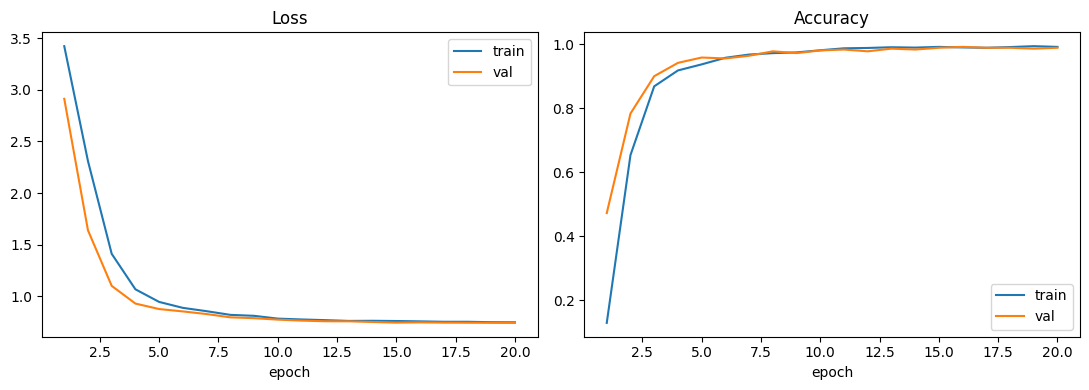

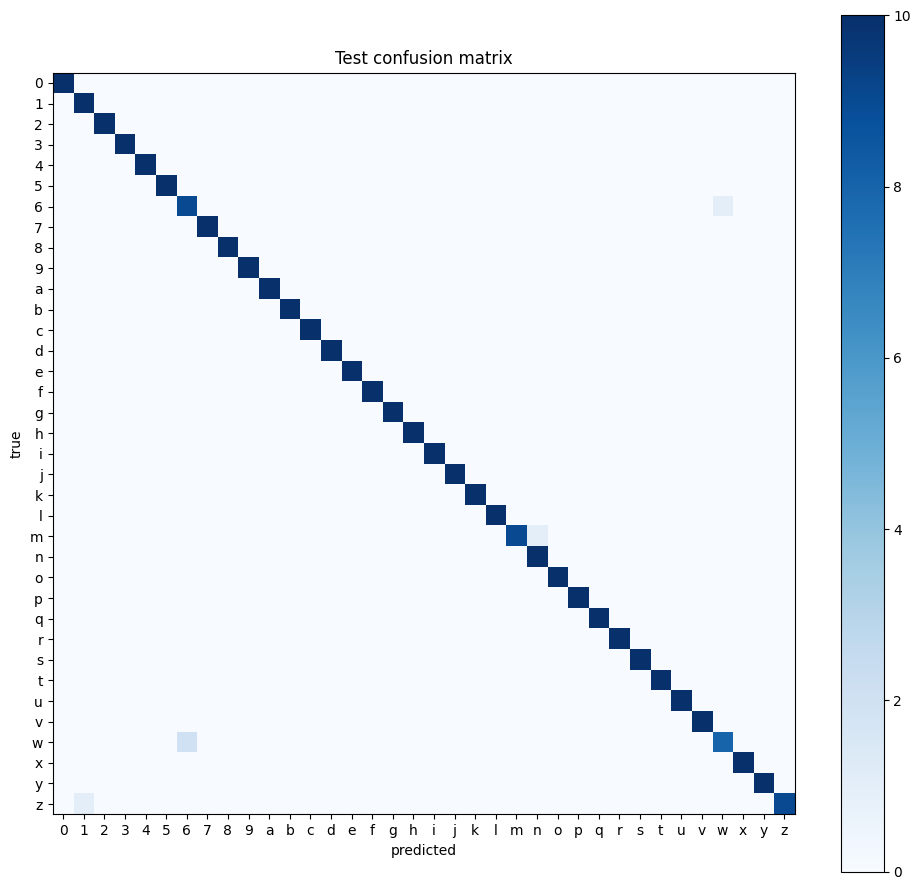

              precision    recall  f1-score   support

           0      1.000     1.000     1.000        10
           1      0.909     1.000     0.952        10
           2      1.000     1.000     1.000        10
           3      1.000     1.000     1.000        10
           4      1.000     1.000     1.000        10
           5      1.000     1.000     1.000        10
           6      0.818     0.900     0.857        10
           7      1.000     1.000     1.000        10
           8      1.000     1.000     1.000        10
           9      1.000     1.000     1.000        10
           a      1.000     1.000     1.000        10
           b      1.000     1.000     1.000        10
           c      1.000     1.000     1.000        10
           d      1.000     1.000     1.000        10
           e      1.000     1.000     1.000        10
           f      1.000     1.000     1.000        10
           g      1.000     1.000     1.000        10
           h      1.000    

In [7]:
import json, numpy as np, matplotlib.pyplot as plt
h = json.load(open(f"{OUT}/history.json"))
ep = [r["epoch"] for r in h]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep, [r["train_loss"] for r in h], label="train"); ax[0].plot(ep, [r["val_loss"] for r in h], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(ep, [r["train_acc"] for r in h], label="train"); ax[1].plot(ep, [r["val_acc"] for r in h], label="val")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{OUT}/curves.png", dpi=150); plt.show()

cm = json.load(open(f"{OUT}/confusion_matrix.json"))
M, cls = np.array(cm["cm"]), cm["classes"]
plt.figure(figsize=(10, 9)); plt.imshow(M, cmap="Blues")
plt.xticks(range(len(cls)), cls); plt.yticks(range(len(cls)), cls)
plt.xlabel("predicted"); plt.ylabel("true"); plt.title("Test confusion matrix"); plt.colorbar()
plt.tight_layout(); plt.savefig(f"{OUT}/confusion_matrix.png", dpi=150); plt.show()
print(open(f"{OUT}/test_report.txt").read())

## 8. Try it on your own image

In [8]:
from google.colab import files
up = files.upload()
for name in up:
    !python -W ignore finetune_rapidnet_asl.py --predict "{name}" --checkpoint {OUT}/best.pth 2>/dev/null

Saving hand1_e_bot_seg_4_cropped.jpeg to hand1_e_bot_seg_4_cropped.jpeg
hand1_e_bot_seg_4_cropped.jpeg:
    e   91.5%
    m    0.7%
    b    0.5%
    j    0.5%
    d    0.5%


## 9. Save results to Google Drive (Colab files are deleted when the session ends)

In [9]:
from google.colab import drive
drive.mount("/content/drive")
!mkdir -p /content/drive/MyDrive/RapidNet_ASL && cp -r {OUT} /content/drive/MyDrive/RapidNet_ASL/
!ls /content/drive/MyDrive/RapidNet_ASL/

Mounted at /content/drive
RapidNet_Ti_stage2


## 10. (Optional) Export to CoreML for the iPhone
Runs on Colab's Linux; the `.mlpackage` is saved into the run folder.

In [10]:
!pip -q install coremltools
import sys; sys.argv = ["x"]; sys.path.insert(0, "/content/RapidNet-Official")
import finetune_rapidnet_asl as F
model, ck = F.load_finetuned(f"{OUT}/best.pth")
F.export_coreml(model, ck["classes"], ck["img_size"], f"{OUT}/RapidNet_ASL.mlpackage")
!cd {OUT} && zip -qr RapidNet_ASL.mlpackage.zip RapidNet_ASL.mlpackage && ls -lh

/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/timm/models/registry.py:4: FutureWarning: Importing from timm.models.registry is deprecated, please import via timm.models
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.models", FutureWarning)
Running MIL backend_mlprogram pipeline: 100%|██████████| 12/12 [00:00<00:00, 98.76 passes/s]


[export] saved /content/runs/RapidNet_Ti_stage2/RapidNet_ASL.mlpackage
total 32M
-rw-r--r-- 1 root root  22M Nov 21 10:33 best.pth
-rw-r--r-- 1 root root 4.1K Nov 21 10:34 confusion_matrix.json
-rw-r--r-- 1 root root  49K Nov 21 10:34 confusion_matrix.png
-rw-r--r-- 1 root root  56K Nov 21 10:34 curves.png
-rw-r--r-- 1 root root 3.3K Nov 21 10:34 history.json
drwxr-xr-x 3 root root 4.0K Nov 21 10:36 RapidNet_ASL.mlpackage
-rw-r--r-- 1 root root  10M Nov 21 10:36 RapidNet_ASL.mlpackage.zip
-rw-r--r-- 1 root root 2.2K Nov 21 10:34 test_report.txt
